# 아래텍스트는 삭제예정



* 2. 지하철 연관 EDA
   - subway_boarding ↔ rent_count
   - subway_alighting ↔ return_count
   - subway_boarding ↔ net_flow
   - subway_alighting ↔ net_flow
   - distance_to_subway ↔ rent_count
   - distance_to_subway ↔ return_count

* 3. 시간대별로 따로 보기
   - 전체 시간대 상관만 보면 의미가 섞일 수 있어.
   - 특히
     - 06시
     - 07시
     - 08시
     - 09시
     - 10시
   - 각각 따로 비교해.

* 4. 출근시간 여부 변수 만들기
   - 우선 가설로 07\~09시 또는 06~10시
   - 실제 EDA에서 피크를 보고 최종 범위 결정
   - is_commute_time
   
* 5. 대여소 거리 구간화
   - 예:
     - 0~200m
     - 200~500m
     - 500m 이상
   - 거리별 평균 대여/반납량 비교
   - “지하철 가까우면 진짜 따릉이 수요가 다른가?” 확인
*6. 최종 EDA 결론 만들기
      결과마다 반드시 한 줄 결론을 붙여.
      예:
   - “08시 역 승차인원이 많을수록 인근 대여소 대여량 증가 경향 확인”
   - “역과의 거리가 멀어질수록 출근시간 대여량 감소”
   - “하차량과 반납량 관계는 약함”
   - “일부 역세권에서만 관계가 강해 지역별 차이 존재”
그리고 네 최종 산출물은 그래프만 있으면 안 되고, 아래처럼 끝내면 좋아.
|가설|	EDA 결과|	변수 후보	|판단|
|--|--|--|--|
|지하철 승차량이 많으면 대여량 증가|	08시 강한 양의 관계|	subway_boarding|	채택 후보
|지하철 하차량이 많으면 반납량 증가|	약한 관계|	subway_alighting|	보류|
|역과 가까울수록 대여량 증가|	200m 이내 높음|distance_to_subway|	채택 후보|
|출근시간에 패턴이 강해짐|	07~09시 뚜렷|is_commute_time|	채택 후보|


즉 네가 지금 만들어야 하는 결과물은 “지하철이 따릉이 수요에 영향을 줄 가능성이 있는지, 어떤 시간대·어떤 거리에서 강한지”를 증명하는 EDA야.
그리고 그다음 모델링에서 subway_boarding, distance_to_subway, is_commute_time 같은 변수를 실제로 넣어보면 돼.

## DB

In [ ]:
# [DB 연결 1] postgresql 연결 라이브러리 설치
%pip install psycopg2-binary

In [ ]:
# [DB 연결 2] 라이브러리
import getpass
import threading
import time
import io
import psycopg2         # PostgreSQL 접속
import re


import pandas as pd
import numpy as np

In [ ]:
host   = "0.tcp.jp.ngrok.io"    # ← ngrok에 표시된 호스트 (tcp:// 제외)
port   = 11189                   # ← ngrok에 표시된 포트
dbname = "bicycle_db"
user   = "BICYCLE_ADMIN"
pw     = getpass.getpass("비밀번호: ")



def _connect():
    return psycopg2.connect(
        host=host, port=port, dbname=dbname, user=user, password=pw,
        connect_timeout=15,
        keepalives=1, keepalives_idle=30,          # 연결 유지용 TCP keepalive
        keepalives_interval=10, keepalives_count=5,
    )

conn = _connect()


def ensure_conn():
    """연결이 끊겼으면 재접속 (청크 사이에 호출)"""
    global conn
    try:
        if conn.closed:
            raise psycopg2.InterfaceError("closed")
        with conn.cursor() as cur:
            cur.execute("SELECT 1")
        conn.rollback()                             # 확인용 트랜잭션 정리
    except Exception:
        try:
            conn.close()
        except Exception:
            pass
        conn = _connect()
        print("[재접속 완료]")

with conn.cursor() as cur:
    cur.execute("SELECT current_user, version()")
    print("접속 성공:", cur.fetchone())
conn.rollback()

비밀번호: ··········
접속 성공: ('BICYCLE_ADMIN', 'PostgreSQL 18.6 on x86_64-windows, compiled by msvc-19.44.35229, 64-bit')


In [ ]:
# 접속한 사용자와 DB 버전 확인 (PostgreSQL)
with conn.cursor() as cur:
    cur.execute("SELECT current_user, current_database(), version()")
    connected_user, db_name, db_version = cur.fetchone()
conn.rollback()

print("PostgreSQL 연결 성공")
print("접속 사용자:", connected_user)
print("접속 DB:", db_name)
print("버전:", db_version)

PostgreSQL 연결 성공
접속 사용자: BICYCLE_ADMIN
접속 DB: bicycle_db
버전: PostgreSQL 18.6 on x86_64-windows, compiled by msvc-19.44.35229, 64-bit


In [ ]:
# 한글폰트 설정
!sudo apt-get -qq install -y fonts-nanum
import matplotlib.font_manager as fm
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")

## 공통함수


In [ ]:
# ============================================================
# [DB 조회] SQL 결과를 DataFrame으로 변환하는 함수
#   - 컬럼명은 PostgreSQL 규칙대로 소문자로 반환됨 (예: rental_date)
#   - %s 는 파라미터 자리 (SQL 인젝션 방지, 값은 params 리스트로 전달)
# ============================================================
def query_df(sql, params=None):
    """SQL 결과 전체를 DataFrame으로 반환 (결과가 작을 때 사용)"""
    ensure_conn()                                   # 연결이 끊겼으면 재접속
    try:
        with conn.cursor() as cur:
            cur.execute(sql, params)
            cols = [d[0] for d in cur.description]
            rows = cur.fetchall()
    finally:
        conn.rollback()                             # 읽기 전용이므로 트랜잭션 정리
    return pd.DataFrame(rows, columns=cols)


def iter_query(sql, params=None, chunk_rows=500_000):
    """SQL 결과를 chunk_rows 행씩 DataFrame으로 반환하는 제너레이터 (대용량 처리용)
    서버사이드 커서를 써서 DB가 결과를 조금씩 보내므로 메모리를 거의 쓰지 않음"""
    ensure_conn()
    cur = conn.cursor(name="stream_cur")            # name 지정 = 서버사이드 커서
    cols = None
    try:
        cur.execute(sql, params)
        while True:
            rows = cur.fetchmany(chunk_rows)
            if not rows:
                break
            if cols is None:                        # 첫 fetch 이후에 컬럼 정보가 채워짐
                cols = [d[0] for d in cur.description]
            yield pd.DataFrame(rows, columns=cols)
    finally:
        cur.close()
        conn.rollback()

# 1\. 기본 EDA


   - 시간대별 전체 대여량/반납량
   - 평일 시간대별 패턴
   - 대여소별 대여량/반납량
   - 대여소별 net_flow
   - 출근시간대 순유출 상위 대여소
   - 출근시간대 순유입 상위 대여소


   - 시간대별 전체 대여량/반납량

In [ ]:
# 그래프 스타일과 함수
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ---- 색·글자 토큰 (검증 통과: 파랑/주황/청록 3색, 파랑↔빨강 양극) ----
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, RED  = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"

_has_nanum = any("NanumGothic" in f.name for f in fm.fontManager.ttflist)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.unicode_minus": False,
    **({"font.family": "NanumGothic"} if _has_nanum else {}),
})
_thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")

def _title(ax, text, sub=None):
    """제목은 왼쪽 정렬, 부제목은 축 위 5pt 고정 간격(그래프 높이와 무관하게 겹치지 않음)"""
    ax.set_title(text, loc="left", color=INK, fontsize=13, fontweight="bold", pad=26 if sub else 10)
    if sub:
        ax.annotate(sub, (0, 1), xycoords="axes fraction", xytext=(0, 5), textcoords="offset points",
                    color=INK2, fontsize=9, va="bottom")

def plot_hourly_all(df):
    """[1-1] 시간대별 하루 평균 대여·반납 (선 2개)"""
    fig, ax = plt.subplots(figsize=(9, 4.8))

    for col, color, name, dy in [("avg_rent_per_day", BLUE, "대여", 10), ("avg_return_per_day", ORANGE, "반납", -16)]:
        ax.plot(df["hour"], df[col], color=color, lw=2, label=name)
        i = df[col].idxmax()                                       # 피크 지점만 직접 라벨
        ax.scatter([df.loc[i, "hour"]], [df.loc[i, col]], s=45, color=color, edgecolor=SURFACE, linewidth=2, zorder=3)
        ax.annotate(f"{name} 피크 {int(df.loc[i, 'hour'])}시 · {df.loc[i, col]:,.0f}건",
                    (df.loc[i, "hour"], df.loc[i, col]), xytext=(10, dy), textcoords="offset points",
                    color=INK2, fontsize=9)
    ax.set_xticks(range(0, 24, 2)); ax.set_xlim(-0.5, 23.5); ax.set_ylim(bottom=0)
    ax.set_xlabel("시간(시)"); ax.set_ylabel("하루 평균 건수 (전체 대여소 합)")
    ax.yaxis.set_major_formatter(_thousands)
    ax.legend(frameon=False, loc="upper left", labelcolor=INK2)
    _title(ax, "시간대별 하루 평균 대여·반납 건수", "전체 기간 · 모든 요일 · 전체 대여소 합계")
    fig.tight_layout(); plt.show()

def plot_hourly_daytype(df):
    """[1-2] 평일/주말/공휴일 시간대 패턴: 대여|반납 두 칸, 같은 y축"""
    kinds = [("weekday", "평일", BLUE), ("weekend", "주말", ORANGE), ("holiday", "공휴일", AQUA)]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
    for ax, col, ttl in [(axes[0], "avg_rent_per_day", "대여"), (axes[1], "avg_return_per_day", "반납")]:
        for key, name, color in kinds:
            d = df[df["day_type"] == key].sort_values("hour")
            if d.empty:
                continue
            ax.plot(d["hour"], d[col], color=color, lw=2, label=f"{name} ({int(d['n_days'].iloc[0]):,}일)")
            j = d[col].idxmax()                                      # 청록 대비 경고 보완: 선마다 직접 라벨
            ax.annotate(name, (d.loc[j, "hour"], d.loc[j, col]), xytext=(6, 4), textcoords="offset points",
                        color=INK2, fontsize=9)
        ax.set_xticks(range(0, 24, 3)); ax.set_xlim(-0.5, 23.5); ax.set_ylim(bottom=0)
        ax.set_xlabel("시간(시)"); ax.yaxis.set_major_formatter(_thousands)
        ax.set_title(ttl, loc="left", color=INK, fontsize=11, fontweight="bold")
    axes[0].set_ylabel("하루 평균 건수 (전체 대여소 합)")
    axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
    fig.suptitle("요일구분별 시간대 패턴 — 평일 출근시간 피크가 주말·공휴일에도 있는가", x=0.01, ha="left",
                 color=INK, fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

def plot_station_scatter(df):
    """[1-3,1-4] 대여소별 월평균 대여 vs 반납. 대각선 위 = 반납 우세(순유입), 아래 = 대여 우세(순유출)"""
    fig, ax = plt.subplots(figsize=(6.6, 6.2))
    ax.scatter(df["rent_per_month"], df["return_per_month"], s=16, color=BLUE, alpha=0.4, edgecolor="none")
    m = float(max(df["rent_per_month"].max(), df["return_per_month"].max()))
    ax.plot([0, m], [0, m], color=INK2, lw=1, ls="--")
    ax.text(m * 0.98, m * 0.93, "대여 = 반납", ha="right", color=INK2, fontsize=9)
    ax.set_xlim(0, m * 1.02); ax.set_ylim(0, m * 1.02); ax.set_aspect("equal")
    ax.set_xlabel("월평균 대여 건수"); ax.set_ylabel("월평균 반납 건수")
    ax.xaxis.set_major_formatter(_thousands); ax.yaxis.set_major_formatter(_thousands)
    _title(ax, "대여소별 월평균 대여 vs 반납", f"점 하나 = 대여소 1곳 ({len(df):,}곳)")
    fig.tight_layout(); plt.show()

def plot_commute_netflow(df, top_n=15, hours_label="07~09시"):
    """[1-5,1-6] 출근시간대 평일 순유입/순유출 상위. 파랑 = 순유입, 빨강 = 순유출, 0 기준선"""
    inn = df.sort_values("net_flow_per_day", ascending=False).head(top_n)
    out = df.sort_values("net_flow_per_day").head(top_n)
    d = pd.concat([inn, out]).sort_values("net_flow_per_day", ascending=False).reset_index(drop=True)
    names = d["station_name"].fillna(d["station_id"]).astype(str).str.slice(0, 16)
    colors = np.where(d["net_flow_per_day"] >= 0, BLUE, RED)
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(d) + 1.8))
    ax.barh(range(len(d)), d["net_flow_per_day"], color=colors, height=0.68, edgecolor=SURFACE, linewidth=2)
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(names, fontsize=9); ax.invert_yaxis()
    ax.grid(axis="y", visible=False); ax.margins(x=0.1)          # 끝 값 라벨이 눈금 글자에 닿지 않게 여백
    for i in (0, len(d) - 1):                                          # 양 끝 값만 직접 라벨
        v = d.loc[i, "net_flow_per_day"]
        ax.annotate(f"{v:+,.1f}", (v, i), xytext=(5 if v >= 0 else -5, 0), textcoords="offset points",
                    ha="left" if v >= 0 else "right", va="center", color=INK2, fontsize=9)
    ax.set_xlabel("평일 하루당 순유입 (반납 − 대여, 건)")
    ax.legend(handles=[Patch(color=BLUE, label="순유입 (반납 > 대여)"), Patch(color=RED, label="순유출 (대여 > 반납)")],
              frameon=False, loc="lower right", labelcolor=INK2)
    _title(ax, f"출근시간대({hours_label}) 평일 순유입·순유출 상위 {top_n}곳씩", "순유입 = 자전거가 쌓이는 곳, 순유출 = 빠져나가는 곳")
    fig.tight_layout(); plt.show()

In [ ]:
# EDA에 쓰는 집계 테이블(mart_station_month_hour)이 60개월(2021-01~2025-12) 전체로 채워졌는지 확인
chk = query_df("""SELECT COUNT(DISTINCT ym) AS months, MIN(ym) AS first_ym, MAX(ym) AS last_ym,
                         SUM(rent_count) AS rent_total, COUNT(*) AS n_rows
                  FROM mart_station_month_hour""")
display(chk)
assert int(chk["months"][0]) == 60, (
    f"집계가 {int(chk['months'][0])}개월분뿐입니다(60개월이어야 함). "
    "2.data_processing 의 build_months(months) 를 끝까지 실행한 뒤 다시 하세요.")

,months,first_ym,last_ym,rent_total,n_rows
0,60,202101,202512,199133389,9010159


####1-1\. 시간대별 전체 대여량/반납량

,hour,rent_total,return_total,avg_rent_per_day,avg_return_per_day
0,0,4149672,4619776,2272.5,2530.0
1,1,2804626,3224056,1535.9,1765.6
2,2,1827010,2132335,1000.6,1167.8
3,3,1258608,1418456,689.3,776.8
4,4,1042169,1084248,570.7,593.8
5,5,1862318,1606169,1019.9,879.6
6,6,3981653,3368799,2180.5,1844.9
7,7,9506462,8055169,5206.2,4411.4
8,8,14276957,14499428,7818.7,7940.5
9,9,8396445,8532268,4598.3,4672.7


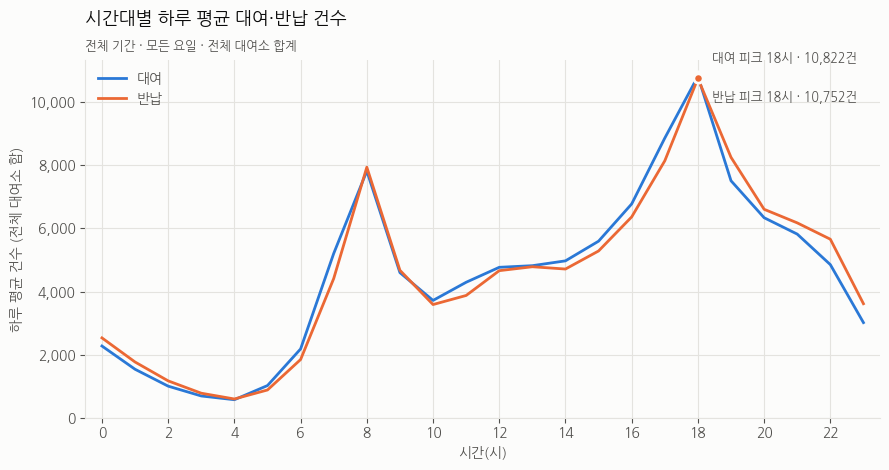

In [ ]:
# 하루 평균 = 시간대별 총건수 ÷ 전체 일수 (월·요일유형별 n_days를 중복 없이 합산)
df_hourly_all = query_df("""
WITH dd AS (
    SELECT SUM(n_days) AS days
    FROM (SELECT DISTINCT ym, day_type, n_days FROM mart_station_month_hour) z
)
SELECT a.hour,
       SUM(a.rent_count)   AS rent_total,
       SUM(a.return_count) AS return_total,
       ROUND(SUM(a.rent_count)::numeric   / dd.days, 1)::float8 AS avg_rent_per_day,
       ROUND(SUM(a.return_count)::numeric / dd.days, 1)::float8 AS avg_return_per_day
FROM mart_station_month_hour a CROSS JOIN dd
GROUP BY a.hour, dd.days
ORDER BY a.hour
""")
display(df_hourly_all)
plot_hourly_all(df_hourly_all)

####1-2\. 평일·주말·공휴일 시간대별 패턴

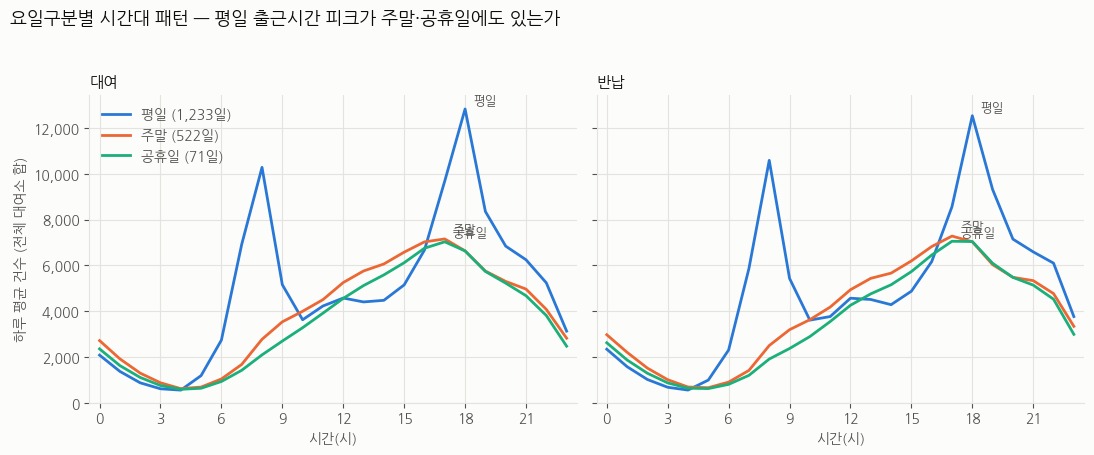

,hour,avg_rent_per_day
42,18,12835.5
32,8,10285.2
41,17,9690.8
43,19,8356.8
31,7,6920.4


,hour,avg_return_per_day
42,18,12540.9
32,8,10591.6
43,19,9316.8
41,17,8569.8
44,20,7148.5


In [ ]:
# 요일유형(weekday/weekend/holiday)별 하루 평균. n_days는 해당 유형의 일수
df_hourly_daytype = query_df("""
SELECT a.day_type, a.hour,
       SUM(a.rent_count)   AS rent_total,
       SUM(a.return_count) AS return_total,
       d.days AS n_days,
       ROUND(SUM(a.rent_count)::numeric   / d.days, 1)::float8 AS avg_rent_per_day,
       ROUND(SUM(a.return_count)::numeric / d.days, 1)::float8 AS avg_return_per_day
FROM mart_station_month_hour a
JOIN (SELECT day_type, SUM(n_days) AS days
      FROM (SELECT DISTINCT ym, day_type, n_days FROM mart_station_month_hour) z
      GROUP BY day_type) d USING (day_type)
GROUP BY a.day_type, a.hour, d.days
ORDER BY a.day_type, a.hour
""")
plot_hourly_daytype(df_hourly_daytype)

# 평일 기준 대여·반납 피크 시간대 → COMMUTE_HOURS 결정에 사용
wk = df_hourly_daytype[df_hourly_daytype["day_type"] == "weekday"]
display(wk.nlargest(5, "avg_rent_per_day")[["hour", "avg_rent_per_day"]])
display(wk.nlargest(5, "avg_return_per_day")[["hour", "avg_return_per_day"]])

####1-3·1-4\. 대여소별 대여량/반납량, net_flow

전체 대여소: 3065


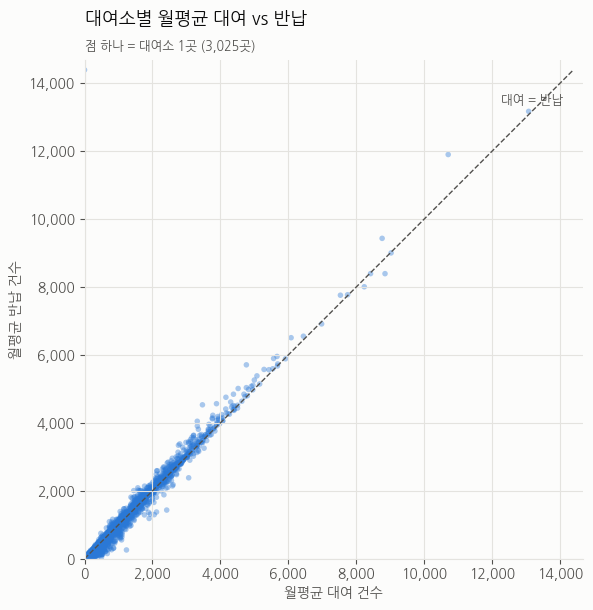

,station_id,rent_total,return_total,net_flow,rent_per_month,return_per_month
2465,ST-385,145256,86017,-59239,2420.9,1433.6
2156,ST-318,74108,15506,-58602,1235.1,258.4
2600,ST-523,123217,77841,-45376,2053.6,1297.4
182,ST-1197,127237,82600,-44637,2120.6,1376.7
2472,ST-391,114166,71174,-42992,1902.8,1186.2
2521,ST-445,184066,143037,-41029,3067.8,2384.0
626,ST-1672,116263,78731,-37532,1937.7,1312.2
980,ST-2028,51536,18866,-32670,858.9,314.4
532,ST-1575,51009,18501,-32508,850.2,308.4
2747,ST-674,65462,33276,-32186,1091.0,554.6


,station_id,rent_total,return_total,net_flow,rent_per_month,return_per_month
2768,ST-699,165957,200607,34650,2766.0,3343.5
988,ST-2035,199394,234499,35105,3323.2,3908.3
986,ST-2033,249878,285389,35511,4164.6,4756.5
1857,ST-2905,526018,566248,40230,8767.0,9437.5
2532,ST-455,233257,274012,40755,3887.6,4566.9
2566,ST-492,199276,242959,43683,3321.3,4049.3
755,ST-18,286075,342704,56629,4767.9,5711.7
1193,ST-2264,208430,272043,63613,3473.8,4534.1
3056,ST-99,642784,714416,71632,10713.1,11906.9
0,\N,0,864018,864018,0.0,14400.3


In [ ]:
# net_flow = 반납 − 대여 (음수 = 순유출). 월평균 = 합계 ÷ 60개월
MIN_TRIPS = 1000          # 이용이 너무 적은 대여소는 제외
df_station = query_df("""
SELECT station_id,
       SUM(rent_count)   AS rent_total,
       SUM(return_count) AS return_total,
       SUM(return_count) - SUM(rent_count) AS net_flow,
       ROUND(SUM(rent_count)::numeric   / 60, 1)::float8 AS rent_per_month,
       ROUND(SUM(return_count)::numeric / 60, 1)::float8 AS return_per_month
FROM mart_station_month_hour
GROUP BY station_id
""")
print("전체 대여소:", len(df_station))
plot_station_scatter(df_station[(df_station["rent_total"] + df_station["return_total"]) >= MIN_TRIPS])
display(df_station.sort_values("net_flow").head(10))     # 순유출 상위
display(df_station.sort_values("net_flow").tail(10))     # 순유입 상위

####1-5·1-6\. 출근시간대 순유출/순유입 상위 대여소

In [ ]:
# 1-2의 평일 피크를 보고 확정할 가설값. 지금은 07~09시
COMMUTE_HOURS = [7, 8, 9]
TOP_N = 15

df_commute = query_df("""
SELECT a.station_id, s.station_name,
       SUM(a.rent_count) AS rent_total, SUM(a.return_count) AS return_total,
       ROUND((SUM(a.return_count) - SUM(a.rent_count))::numeric / d.days, 2)::float8 AS net_flow_per_day
FROM mart_station_month_hour a
JOIN (SELECT SUM(n_days) AS days
      FROM (SELECT DISTINCT ym, n_days FROM mart_station_month_hour WHERE day_type = 'weekday') z) d ON TRUE
LEFT JOIN station_both s ON s.station_id = a.station_id
WHERE a.day_type = 'weekday' AND a.hour = ANY(%s)
GROUP BY a.station_id, s.station_name, d.days
HAVING SUM(a.rent_count) + SUM(a.return_count) >= %s
""", (COMMUTE_HOURS, MIN_TRIPS))
plot_commute_netflow(df_commute, TOP_N, "07~09시")

UndefinedColumn: 오류:  s.station_id 칼럼 없음
LINE 8: LEFT JOIN station_both s ON s.station_id = a.station_id
                                    ^
HINT:  아마 "a.station_id" 칼럼을 참조하는 것 같습니다.


####1-7\. 집계 결과 검증

In [ ]:
print("하루 평균 총 대여:", round(df_hourly_all["avg_rent_per_day"].sum()))   # ≈ 109,000
print("하루 평균 총 반납:", round(df_hourly_all["avg_return_per_day"].sum()))
print("net_flow 합계:", int(df_station["net_flow"].sum()))                    # ≈ 0

하루 평균 총 대여: 109054
하루 평균 총 반납: 109054
net_flow 합계: -405


In [ ]:
# 검증 1: 시간대별 하루 평균 대여의 합 = 하루 평균 총 대여 건수
#   기대값: 1.99억 건 ÷ 1,826일(2021-01-01~2025-12-31) ≈ 109,000 (정류장 NULL 제외분만큼 약간 작을 수 있음)
print("하루 평균 총 대여:", round(df_hourly_all["avg_rent_per_day"].sum()))
print("하루 평균 총 반납:", round(df_hourly_all["avg_return_per_day"].sum()))

# 검증 2: 정류장별 net_flow 의 합 ≈ 0 (대여와 반납은 전체로 보면 거의 같음. 기간 밖 반납 등으로 수백 건 차이는 정상)
print("net_flow 합계:", int(df_station["net_flow"].sum()))

하루 평균 총 대여: 109054
하루 평균 총 반납: 109054
net_flow 합계: -405
